<a href="https://colab.research.google.com/github/tisha-gupta/DL_Learnings/blob/Single_Layer_Perceptron/1_Single_perceptron_better_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("placement.csv")

In [3]:
print(df.shape)

(100, 3)


In [4]:
df.head()

,cgpa,resume_score,placed
0,8.14,6.52,1
1,6.17,5.17,0
2,8.27,8.86,1
3,6.88,7.27,1
4,7.52,7.30,1


In [5]:
import seaborn as sns

<Axes: xlabel='cgpa', ylabel='resume_score'>

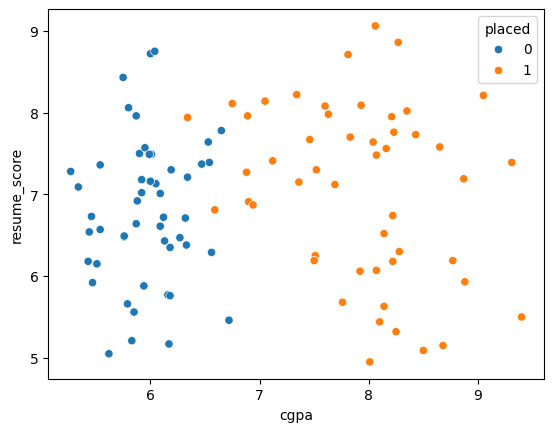

In [6]:
sns.scatterplot(data = df, x = 'cgpa', y = 'resume_score', hue = 'placed')

In [7]:
X = df.iloc[:, :2].values

In [8]:
y = df.iloc[:,-1].values

In [9]:
from sklearn.preprocessing import StandardScaler

In [10]:
scaler = StandardScaler()

In [11]:
X_scaled = scaler.fit_transform(X)

In [12]:
from sklearn.linear_model import Perceptron

In [13]:
p = Perceptron(
    max_iter = 2000,
    eta0 = 0.01,
    early_stopping = True,
    validation_fraction = 0.15,
    random_state = 42
)

In [14]:
p.fit(X_scaled, y)

Perceptron(early_stopping=True, eta0=0.01, max_iter=2000, random_state=42,
           validation_fraction=0.15)

In [15]:
print(f"Optimized Accuracy: {p.score(X_scaled, y):.2%}")
print(f"Weights (scaled space): {p.coef_}")
print(f"Intercept (scaled space): {p.intercept_}")

Optimized Accuracy: 96.00%
Weights (scaled space): [[0.04937005 0.011896  ]]
Intercept (scaled space): [0.01]


In [16]:
from mlxtend.plotting import plot_decision_regions
import matplotlib.pyplot as plt

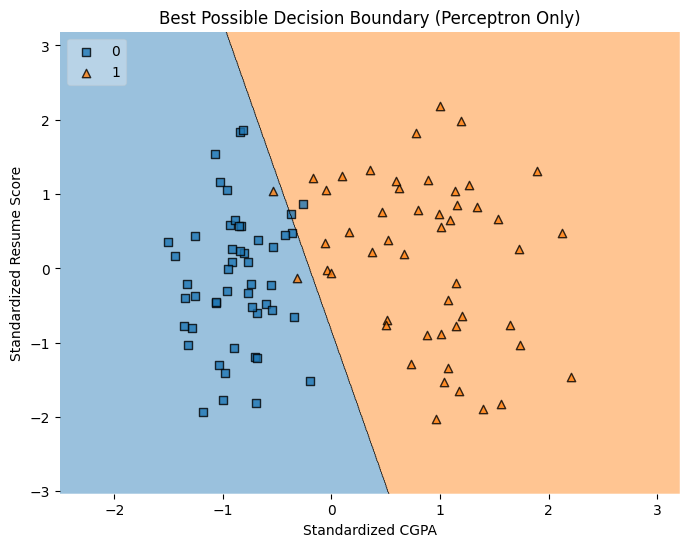

In [17]:
plt.figure(figsize=(8, 6))
plot_decision_regions(X_scaled, y, clf = p, legend = 2)

plt.xlabel('Standardized CGPA')
plt.ylabel('Standardized Resume Score')
plt.title('Best Possible Decision Boundary (Perceptron Only)')
plt.show()
